# Patrol rover: data analysis
Snapshot of the edge hub's SQLite store (`iot/data/hub.db`), copied from the board. Every row here was also forwarded to ThingSpeak and AWS (DynamoDB / S3) through the store-and-forward outbox.

In [1]:
import sqlite3, json, pandas as pd, matplotlib.pyplot as plt
c = sqlite3.connect('hub.db')
t = pd.read_sql('select * from telemetry', c)
p = pd.read_sql('select * from patrols', c)
v = pd.read_sql('select * from verdicts', c)
o = pd.read_sql('select * from outbox', c)
for d in (t, p, v): d['ts'] = pd.to_datetime(d['ts'], unit='s', utc=True).dt.tz_convert('Asia/Kolkata')
pd.Series({'telemetry rows': len(t), 'patrols/searches': len(p), 'verdicts': len(v), 'outbox pending': len(o),
           'span': t.ts.max() - t.ts.min()})

telemetry rows                           5194
patrols/searches                            7
verdicts                                    3
outbox pending                              0
span                0 days 01:28:48.761858464
dtype: object

## Telemetry rate and gaps
The hub polls the rover at 1 Hz. Gaps show when the rover app or hub was down (redeploys, flashing).

In [2]:
dt = t.ts.diff().dt.total_seconds()
print(dt.describe().round(2))
gaps = t.loc[dt > 10, 'ts'].to_frame().assign(gap_s=dt[dt > 10])
gaps

count    5193.00
mean        1.03
std         1.20
min         1.00
25%         1.00
50%         1.00
75%         1.00
max        80.81
Name: ts, dtype: float64


,ts,gap_s
3389,2026-11-22 16:13:07.235775471+05:30,80.808462
4785,2026-11-22 16:37:10.213654280+05:30,34.100250


## Distances over time
`-1` means no valid echo (out of range or stale), so those are dropped from the plot.

Text(0.5, 1.0, 'Ultrasonic distance')

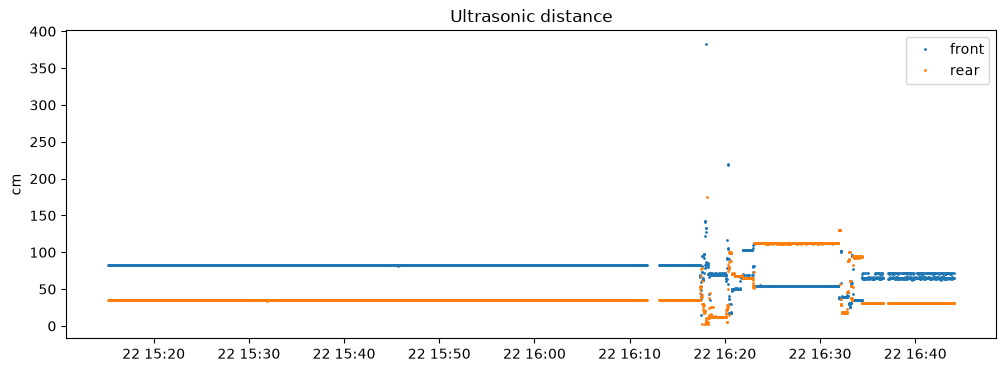

In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
for k in ('front', 'rear'):
    s = t[t[k] > 0]
    ax.plot(s.ts, s[k] / 10, '.', ms=2, label=k)
ax.set_ylabel('cm'); ax.legend(); ax.set_title('Ultrasonic distance')

## Sensor health
Share of samples with a valid reading, and the front-distance spread.

<Axes: title={'center': 'front distance (cm)'}, ylabel='Frequency'>

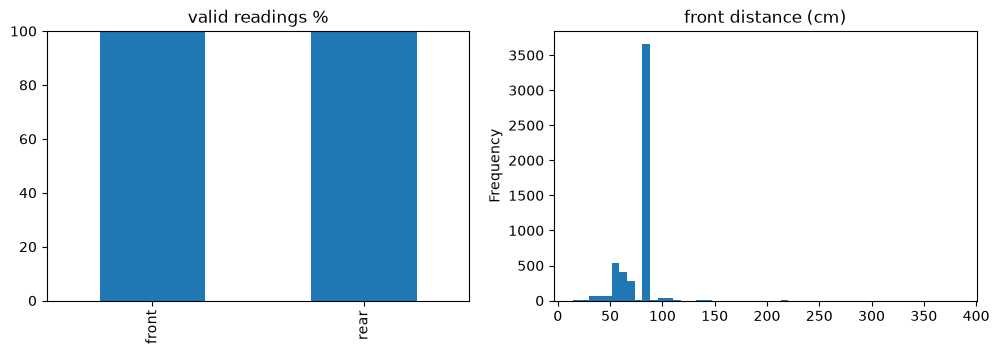

In [4]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.5))
(t[['front', 'rear']] > 0).mean().mul(100).plot.bar(ax=a, title='valid readings %', ylim=(0, 100))
t.loc[t.front > 0, 'front'].div(10).plot.hist(bins=50, ax=b, title='front distance (cm)')

## Heading
Gyro-integrated heading (degrees). `-99999` would mean gyro lost, which aborts a patrol.

gyro-lost samples: 0


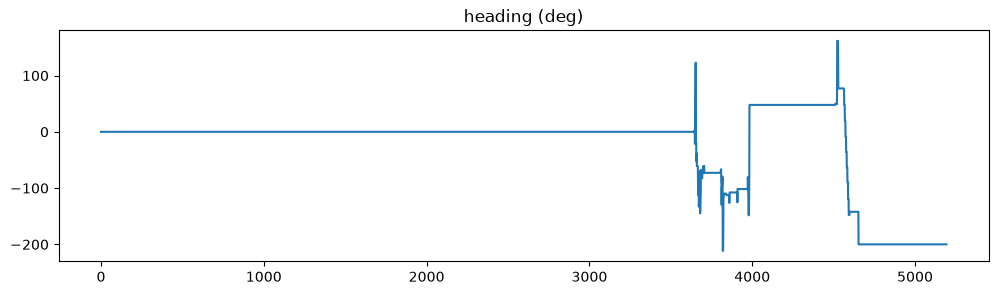

In [5]:
h = t[t.hdg > -9999]
ax = (h.hdg / 10).reset_index(drop=True).plot(figsize=(12, 3), title='heading (deg)')
print('gyro-lost samples:', (t.hdg <= -9999).sum())

## Rover state
Time spent in each state (one sample per second).

<Axes: title={'center': 'samples per state'}, ylabel='patrol'>

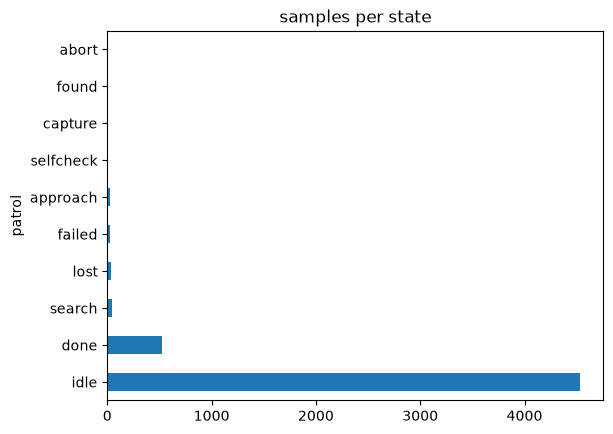

In [6]:
t.patrol.value_counts().plot.barh(title='samples per state')

## Patrols and searches
`p…` = patrol (checkpoint capture + change detection), `s…` = search & rescue (NanoDet object search + approach).

,pid,kind,legs,state,err,ts
0,p20261122-105100,patrol,1,done,,2026-11-22 16:21:05.388059616+05:30
1,p20261122-105149,patrol,1,done,,2026-11-22 16:23:05.792939425+05:30
2,s20261122-110154,search,0,found,,2026-11-22 16:32:03.036761284+05:30
3,s20261122-110203,search,0,found,,2026-11-22 16:32:09.038064957+05:30
4,s20261122-110209,search,0,failed,aborted,2026-11-22 16:32:15.039653301+05:30
5,s20261122-110215,search,0,failed,timeout in approach,2026-11-22 16:32:23.043888092+05:30
6,s20261122-110248,search,0,lost,,2026-11-22 16:33:32.060149908+05:30


<Axes: title={'center': 'outcomes'}, xlabel='kind'>

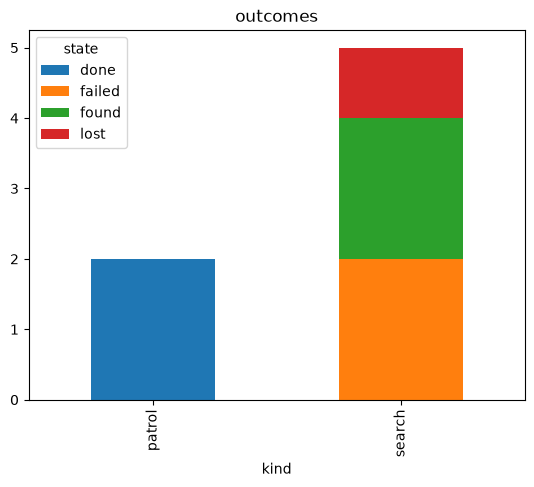

In [7]:
p['kind'] = p.pid.str[0].map({'p': 'patrol', 's': 'search'})
display(p[['pid', 'kind', 'legs', 'state', 'err', 'ts']])
pd.crosstab(p.kind, p.state).plot.bar(stacked=True, title='outcomes')

## Change-detection verdicts
Each checkpoint image is aligned to the previous patrol's image (ORB + RANSAC, ECC refine), then compared with CLAHE + SSIM and an intensity-difference gate. `inliers=0` means alignment failed, which is reported as REVIEW (fail safe), never CLEAR.

In [8]:
v['regions'] = v.regions.map(lambda r: len(json.loads(r)) if r else 0)
v[['pid', 'cp', 'ref', 'verdict', 'inliers', 'ssim', 'changed', 'regions']]

,pid,cp,ref,verdict,inliers,ssim,changed,regions
0,p20261122-093510,0,p20261122-093158,REVIEW,0,NaN,NaN,0
1,p20261122-105100,0,p20261122-093510,REVIEW,0,NaN,NaN,0
2,p20261122-105149,0,p20261122-105100,REVIEW,326,0.672,12.77,4


Text(0, 0.5, '% area changed')

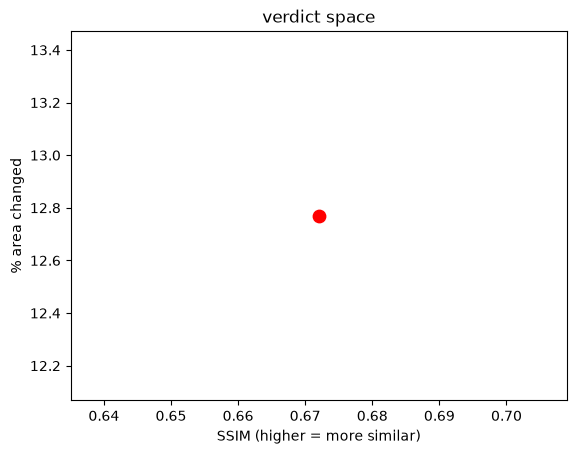

In [9]:
ok = v[v.inliers > 0]
ax = ok.plot.scatter('ssim', 'changed', c=ok.verdict.map({'CLEAR': 'g', 'REVIEW': 'r'}), s=80, title='verdict space')
ax.set_xlabel('SSIM (higher = more similar)'); ax.set_ylabel('% area changed')

## Store-and-forward
Rows waiting in the outbox for AWS / ThingSpeak. Zero means everything recorded reached the cloud.

In [10]:
o.groupby('dest').size() if len(o) else 'outbox empty: all data delivered'

'outbox empty: all data delivered'